# Front-Door Identification through a Mediator

A mediator satisfies the front-door criterion when it intercepts every directed treatment-to-outcome path, has no unblocked back-door path from treatment, and has every back-door path to outcome blocked by treatment:

$$
X\to M\to Y,
\qquad
X\mathbin{\perp\!\!\!\perp}_{G_{\underline X}}M,
\qquad
M\mathbin{\perp\!\!\!\perp}_{G_{\underline M}}Y\mid X.
$$

Here, $X$ is treatment, $M$ is the mediator, $Y$ is outcome, $G_{\underline X}$ removes arrows leaving $X$, $G_{\underline M}$ removes arrows leaving $M$, and the separation statements encode the two required back-door protections.

## Packages and notebook settings

In [ ]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"1.1.0"
configure_plots!()
paths = output_paths("02_graphical_identification");
using CSV, TOML
include(joinpath("..","support","CausalNotebookTools.jl"))
using .CausalNotebookTools
include(joinpath("..","support","BookCausalStudy.jl"))
using .BookCausalStudy
import .BookCausalStudy: frame
using RiskLabAI.CausalFactorAnalysis: d_separation
default(left_margin=10Plots.mm,bottom_margin=10Plots.mm)
input_directory = joinpath("..","data","chapter02_random_inputs");


## Graph structure and path checks

Row,Condition,Required,Built into experiment
,String,String,String
1,Mediator intercepts every directed treatment-outcome path,Yes,Yes
2,No open back-door path from treatment to mediator,Yes,Yes
3,Treatment blocks every mediator-outcome back-door path,Yes,Yes
4,Unmeasured treatment-outcome common cause is allowed,No,Yes


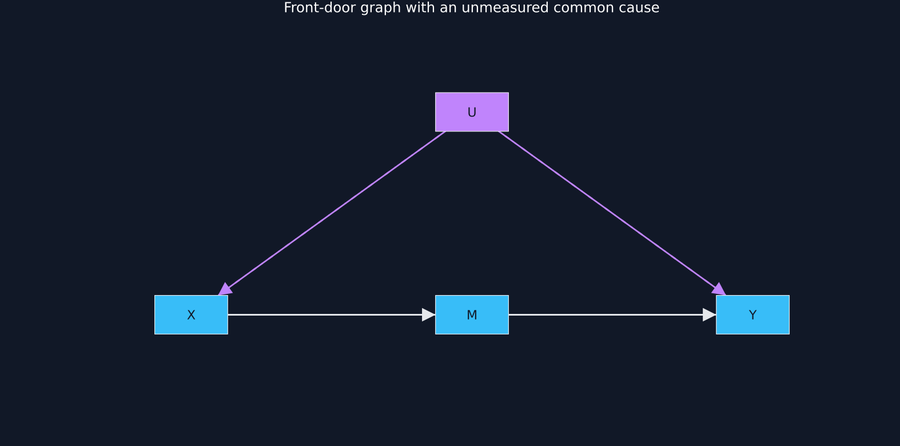

In [1]:
table(values,name,caption) = save_table(values,paths,name;caption,label="tab:chapter24-"*replace(name,"_"=>"-"))
matrix_data(values) = DataFrame(values,:auto)
function assert_artifacts(figures,tables)
    @assert all(name->isfile(joinpath(paths.figures,name*".pdf")),figures)
    @assert all(name->isfile(joinpath(paths.tables,name*".tex")),tables)
end
include(joinpath("..","support","BookIdentificationStudy.jl"))
using .BookIdentificationStudy
function table(values,name,caption)
    shown = copy(values)
    for column in names(shown)
        if all(value->value isa Bool,shown[!,column])
            shown[!,column] = ifelse.(shown[!,column],"Yes","No")
        end
    end
    save_table(shown,paths,name;caption,label="tab:chapter24-"*replace(name,"_"=>"-"))
    return nothing
end
store = PrimitiveStore(input_directory,"frontdoor")
frontdoor_graph = DirectedGraph([("U","X"),("U","Y"),("X","M"),("M","Y")])
positions = Dict("U"=>(1.5,1.1),"X"=>(0.,0.),"M"=>(1.5,0.),"Y"=>(3.,0.))
frontdoor_conditions = frame(["Condition","Required","Built into experiment"],[["Mediator intercepts every directed treatment-outcome path",true,true],["No open back-door path from treatment to mediator",true,true],["Treatment blocks every mediator-outcome back-door path",true,true],["Unmeasured treatment-outcome common cause is allowed",false,true]])
table(frontdoor_conditions,"frontdoor_conditions","Conditions used by the front-door experiment.")
save_figure(plot(identification_graph_panel(frontdoor_graph,positions,"Front-door graph with an unmeasured common cause";latent=["U"]);size=(1050,520)),paths,"frontdoor_graph")


## Comparing nonparametric identification with the linear calculation

Under the front-door conditions, the intervention distribution is expressed with observed treatment, mediator, and outcome distributions:

$$
p(y\mid\operatorname{do}(x))
=\sum_m p(m\mid x)\sum_{x'}p(y\mid m,x')p(x').
$$

Here, $x$ is the treatment value set by intervention, $m$ ranges over mediator values, $x'$ ranges over observed treatment values, $p(m\mid x)$ is the treatment-to-mediator relation, $p(y\mid m,x')$ is the outcome distribution within mediator-treatment groups, and $p(x')$ is the marginal treatment distribution.

In the linear full-mediation case used by the public library, the identified effect is the product of two fitted slopes:

$$
\widehat\beta_{\mathrm{FD}}=\widehat a\,\widehat b,
\qquad
M=\alpha_M+aX+e_M,
\qquad
Y=\alpha_Y+bM+cX+e_Y.
$$

Here, $\widehat\beta_{\mathrm{FD}}$ is the front-door estimate, $\widehat a$ is the fitted slope from mediator on treatment, $\widehat b$ is the mediator coefficient in the outcome equation that also includes treatment, $c$ is the fitted treatment coefficient used only as a warning about a direct path or remaining confounding, and the two $e$ terms are regression residuals.

The known data-generating system allows both treatment-outcome and mediator-outcome common causes as well as an optional direct path:

$$
X=c_UU+\varepsilon_X,\qquad
M=aX+c_VV+\varepsilon_M,\qquad
Y=bM+dX+g_UU+g_VV+\varepsilon_Y.
$$

Here, $U$ is the unmeasured treatment-outcome common cause, $V$ is the optional mediator-outcome common cause, $a$ and $b$ form the mediated effect, $d$ is a direct effect, $c_U$ and $g_U$ are the loadings of $U$, $c_V$ and $g_V$ are the loadings of $V$, and the three $\varepsilon$ terms are independent standard-normal shocks.

Row,Parameter,Symbol,Value
,String,String,Real
1,Observations in released example,n,6000
2,Treatment-to-mediator coefficient,a,0.7
3,Mediator-to-outcome coefficient,b,0.6
4,Known mediated effect,a times b,0.42
5,Treatment-outcome common-cause loading,c U and g U,1.0
6,Reported sensitivity strength,lambda,0.3


Row,Panel,Known effect,Front-door estimate,Ordinary estimate,Sensitivity low,Sensitivity high
,String,Float64,Float64,Float64,Float64,Float64
1,Clean,0.42,0.425817,0.432928,0.272518,0.579116
2,Confounded,0.42,0.423957,0.909748,0.273467,0.574447


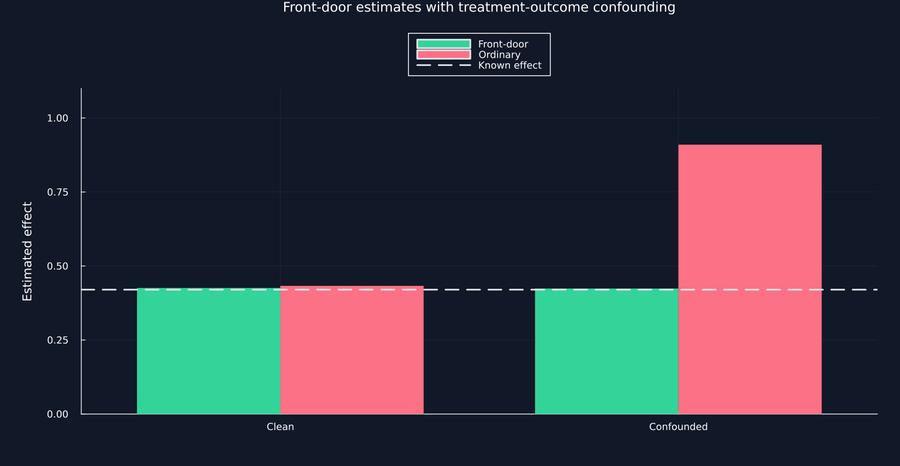

In [2]:
frontdoor_parameters = frame(["Parameter","Symbol","Value"],[["Observations in released example","n",6000],["Treatment-to-mediator coefficient","a",0.7],["Mediator-to-outcome coefficient","b",0.6],["Known mediated effect","a times b",0.42],["Treatment-outcome common-cause loading","c U and g U",1.0],["Reported sensitivity strength","lambda",0.3]])
demo_rows = Tuple[]
for (index,(name,confounding)) in enumerate([("Clean",0.),("Confounded",1.)])
    x,m,y,u,truth = simulate_frontdoor(store,"fd_demo",index;a=.7,b=.6,c_u=confounding,g_u=confounding)
    result = frontdoor_analysis(x,m,y)
    low,high = result.sensitivity[.30]
    push!(demo_rows,(name,truth,result.premium,result.ols_premium,result.wedge,result.a_hat,result.b_hat,low,high))
    save_data(DataFrame(Treatment=x,Mediator=m,Outcome=y,Common=u),paths,"frontdoor_demo_sample_$(index)")
end
frontdoor_demo = frame(["Panel","Known effect","Front-door estimate","Ordinary estimate","Wedge","First slope","Second slope","Sensitivity low","Sensitivity high"],demo_rows)
table(frontdoor_parameters,"frontdoor_structural_parameters","Values used in the released front-door example.")
table(select(frontdoor_demo,["Panel","Known effect","Front-door estimate","Ordinary estimate","Sensitivity low","Sensitivity high"]),"frontdoor_demo","Front-door and ordinary estimates in clean and confounded panels.")
save_data(frontdoor_demo,paths,"frontdoor_demo_details")
figure = bar((1:2).- .18,frontdoor_demo[!,"Front-door estimate"];bar_width=.36,color=palette.green,linealpha=0,label="Front-door",xticks=(1:2,frontdoor_demo.Panel),xlims=(.5,2.5),ylims=(0,1.1),ylabel="Estimated effect",legend=:outertop,title="Front-door estimates with treatment-outcome confounding",size=(1100,570))
bar!(figure,(1:2).+ .18,frontdoor_demo[!,"Ordinary estimate"];bar_width=.36,color=palette.rose,linealpha=0,label="Ordinary")
hline!(figure,[.42];color=palette.text,linestyle=:dash,label="Known effect")
save_figure(figure,paths,"frontdoor_demo_comparison")


## Checking convergence across repeated samples

Repeated-sample error compares the front-door estimate with the ordinary estimate and with a back-door estimate that can use the common cause when it is observed:

$$
\operatorname{MSE}(\widehat\beta)=\frac{1}{R}\sum_{r=1}^{R}(\widehat\beta_r-\beta)^2.
$$

Here, $\operatorname{MSE}$ is mean squared error, $R$ is the number of repeated samples, $\widehat\beta_r$ is an effect estimate in repetition $r$, and $\beta$ is the known effect fixed by the generating equations.

Row,Method,Mean estimate,Bias,Mean squared error,Repetitions
,String,Float64,Float64,Float64,Int64
1,Front-door,0.999912,-8.80014e-5,0.00113554,200
2,Ordinary regression,1.5,0.499999,0.250748,200


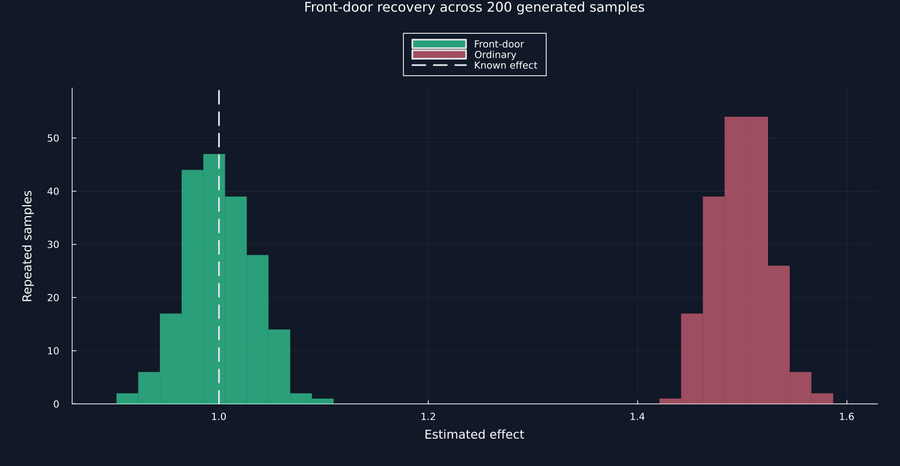

Row,Scenario,Mean estimate,Mean squared error,Repetitions
,String,Float64,Float64,Int64
1,Front-door with measured common cause,0.996139,0.000946705,200
2,Back-door with measured common cause,1.00188,0.000867727,200
3,Front-door without confounding,0.99445,0.000987981,200
4,Ordinary without confounding,0.995706,0.000915723,200


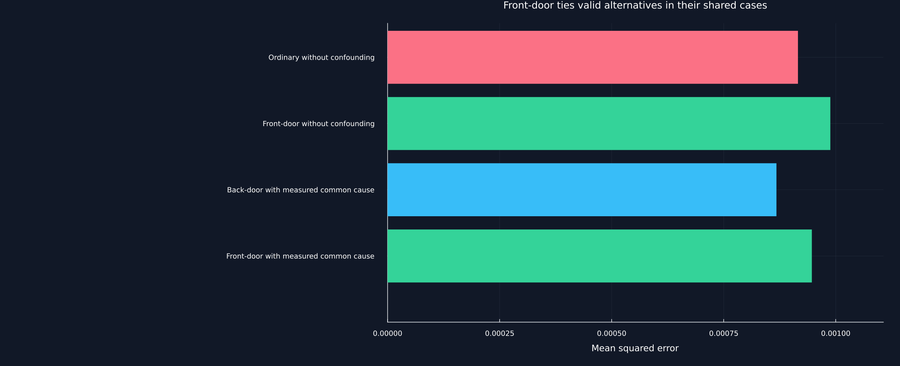

In [3]:
repetitions,observations = 200,2000
fd_values,ordinary_values = zeros(repetitions),zeros(repetitions)
for repetition in 1:repetitions
    x,m,y,u,truth = simulate_frontdoor(store,"fd_recovery",repetition)
    fd_values[repetition] = frontdoor_premium(x,m,y)
    ordinary_values[repetition] = ols_premium(x,y)
end
recovery_summary = frame(["Method","Mean estimate","Bias","Mean squared error","Repetitions"],[(name,mean(values),mean(values)-1.,mean_squared_error(values,1.),repetitions) for (name,values) in [("Front-door",fd_values),("Ordinary regression",ordinary_values)]])
table(recovery_summary,"frontdoor_recovery_summary","Repeated-sample recovery under an unmeasured treatment-outcome common cause.")
save_data(DataFrame("Repetition"=>0:repetitions-1,"Front-door"=>fd_values,"Ordinary regression"=>ordinary_values),paths,"frontdoor_recovery_repetitions")
bins = range(min(minimum(fd_values),minimum(ordinary_values)),max(maximum(fd_values),maximum(ordinary_values));length=34)
histogram_peak = maximum(count(value->bins[index]<=value&&(value<bins[index+1]||(index==length(bins)-1&&value==bins[index+1])),values) for values in [fd_values,ordinary_values] for index in 1:length(bins)-1)
figure = histogram(fd_values;bins,ylims=(0,1.1histogram_peak),alpha=.72,color=palette.green,linealpha=0,label="Front-door",xlabel="Estimated effect",ylabel="Repeated samples",title="Front-door recovery across 200 generated samples",legend=:outertop,size=(1100,570))
histogram!(figure,ordinary_values;bins,alpha=.60,color=palette.rose,linealpha=0,label="Ordinary")
vline!(figure,[1.];color=palette.text,linestyle=:dash,linewidth=2,label="Known effect")
save_figure(figure,paths,"frontdoor_estimate_distributions")
scenario_names = ["Front-door with measured common cause","Back-door with measured common cause","Front-door without confounding","Ordinary without confounding"]
scenario_values = zeros(repetitions,4)
for repetition in 1:repetitions
    x,m,y,u,truth = simulate_frontdoor(store,"fd_convergence",2repetition-1)
    scenario_values[repetition,1] = frontdoor_premium(x,m,y)
    scenario_values[repetition,2] = ols_slope(y,x,u)
    x0,m0,y0,u0,truth0 = simulate_frontdoor(store,"fd_convergence",2repetition;c_u=0.,g_u=0.)
    scenario_values[repetition,3] = frontdoor_premium(x0,m0,y0)
    scenario_values[repetition,4] = ols_premium(x0,y0)
end
convergence_table = frame(["Scenario","Mean estimate","Mean squared error","Repetitions"],[(name,mean(scenario_values[:,index]),mean_squared_error(scenario_values[:,index],1.),repetitions) for (index,name) in enumerate(scenario_names)])
table(convergence_table,"frontdoor_convergence","Convergence comparisons when the common cause is measured or absent.")
save_data(DataFrame(scenario_values,scenario_names),paths,"frontdoor_convergence_repetitions")
figure = bar(1:4,convergence_table[!,"Mean squared error"];orientation=:horizontal,color=[palette.green,palette.cyan,palette.green,palette.rose],linealpha=0,legend=false,yticks=(1:4,scenario_names),xlabel="Mean squared error",xlims=(0,1.12maximum(convergence_table[!,"Mean squared error"])),title="Front-door ties valid alternatives in their shared cases",left_margin=95Plots.mm,size=(1500,610))
save_figure(figure,paths,"frontdoor_convergence_mse")


## Measuring the front-door wedge under sensitivity

The public library measures the gap between the front-door and ordinary estimates with an absolute wedge:

$$
W_{\mathrm{FD}}=\left|\widehat\beta_{\mathrm{FD}}-\widehat\beta_{\mathrm{OLS}}\right|.
$$

Here, $W_{\mathrm{FD}}$ is the diagnostic wedge, $\widehat\beta_{\mathrm{FD}}$ is the front-door product, and $\widehat\beta_{\mathrm{OLS}}$ is the ordinary treatment slope. A large wedge records disagreement under the stated design; it does not prove which assumption failed in an unknown graph.

Row,Common-cause loading,Mean wedge,Wedge standard deviation,Repetitions
,Float64,Float64,Float64,Int64
1,0.0,0.0238611,0.0189812,200
2,1.0,0.498546,0.0351862,200
3,1.5,0.691442,0.035212,200


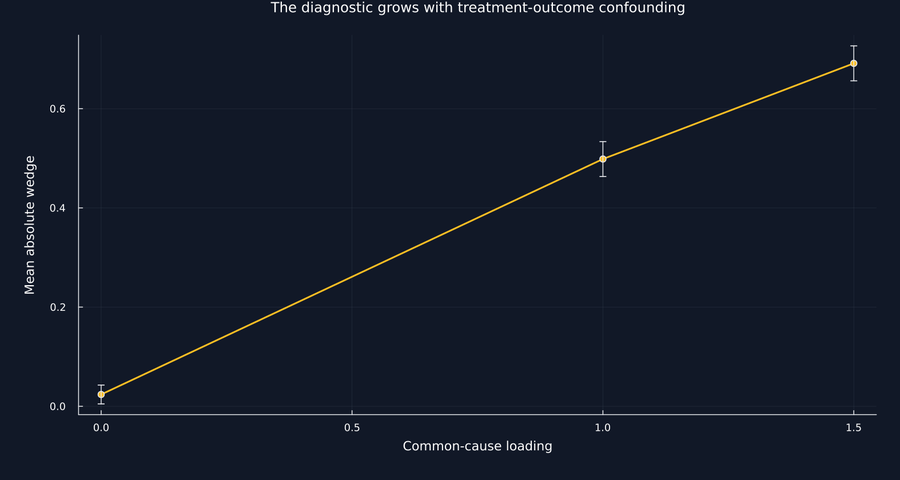

In [4]:
wedge_rows,wedge_repetitions = Tuple[],Tuple[]
for (index,confounding) in enumerate([0.,1.,1.5])
    values = zeros(repetitions)
    for repetition in 1:repetitions
        x,m,y,u,truth = simulate_frontdoor(store,"fd_wedge",(index-1)*repetitions+repetition;c_u=confounding,g_u=confounding)
        values[repetition] = frontdoor_ols_wedge(x,m,y)
        push!(wedge_repetitions,(confounding,repetition-1,values[repetition]))
    end
    push!(wedge_rows,(confounding,mean(values),std(values),repetitions))
end
wedge_sweep = frame(["Common-cause loading","Mean wedge","Wedge standard deviation","Repetitions"],wedge_rows)
table(wedge_sweep,"frontdoor_wedge_sweep","Front-door and ordinary-estimate disagreement as confounding increases.")
save_data(frame(["Common-cause loading","Repetition","Wedge"],wedge_repetitions),paths,"frontdoor_wedge_repetitions")
figure = plot(wedge_sweep[!,"Common-cause loading"],wedge_sweep[!,"Mean wedge"];yerror=wedge_sweep[!,"Wedge standard deviation"],marker=:circle,color=palette.amber,legend=false,xlabel="Common-cause loading",ylabel="Mean absolute wedge",title="The diagnostic grows with treatment-outcome confounding",size=(1050,560))
save_figure(figure,paths,"frontdoor_wedge_sweep")


The library's linear sensitivity interval expands the second-stage coefficient by a declared mediator-outcome confounding strength:

$$
\mathcal I_{\lambda}
=\left[
\widehat a\left(\widehat b-\lambda|\widehat a|-\lambda s_b\right),
\widehat a\left(\widehat b+\lambda|\widehat a|+\lambda s_b\right)
\right].
$$

Here, $\mathcal I_{\lambda}$ is the reported interval, $\lambda\geq0$ is the assumed sensitivity strength, $\widehat a$ is the first-stage mediator slope, $\widehat b$ is the second-stage mediator coefficient, and $s_b$ is the standard error of $\widehat b$. The interval is a warning calculation under this rule, not a test that proves the mediator is protected.

### The warning band must widen before it covers the truth

Row,Sensitivity strength,Coverage,Repetitions
,Float64,Float64,Int64
1,0.0,0.0,200
2,0.15,0.0,200
3,0.3,0.0,200
4,0.45,1.0,200
5,0.6,1.0,200


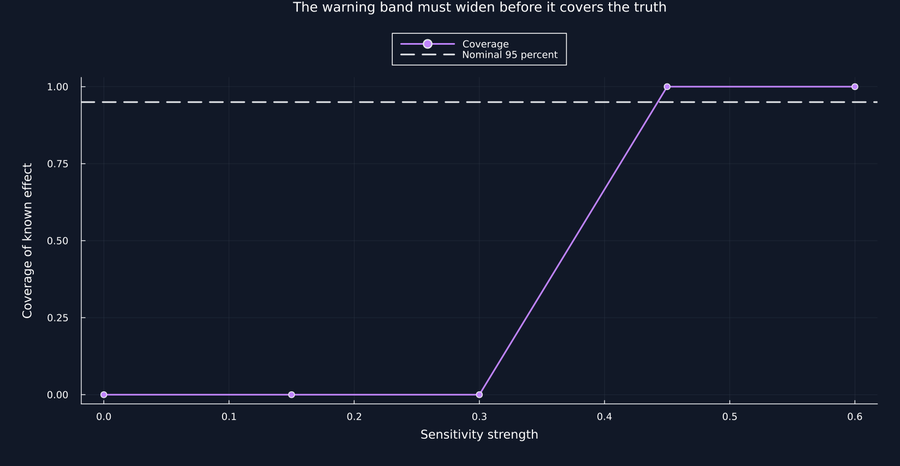

Row,Sensitivity strength,Lower end,Upper end,Width,Contains known effect
,Float64,Float64,Float64,Float64,String
1,0.0,0.984526,0.984526,0.0,No
2,0.15,0.834184,1.13487,0.300684,Yes
3,0.3,0.683842,1.28521,0.601367,Yes
4,0.45,0.5335,1.43555,0.902051,Yes
5,0.6,0.383158,1.58589,1.20273,Yes


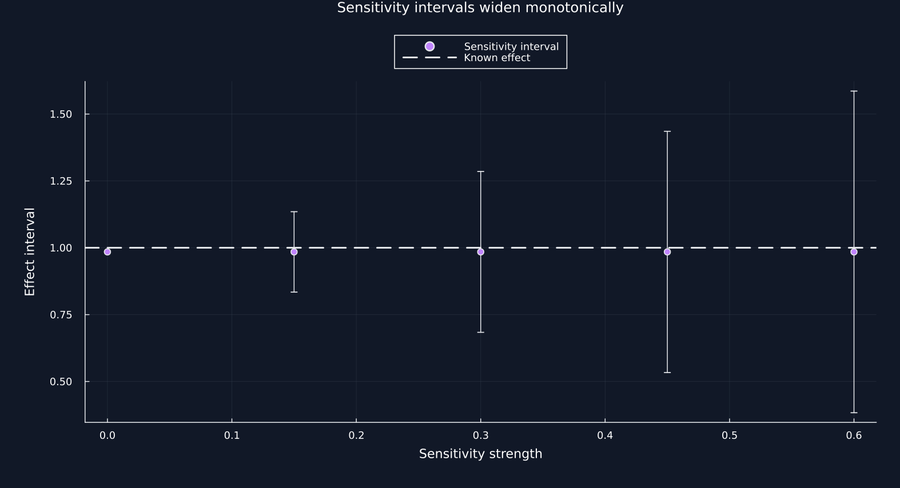

In [5]:
sensitivity_grid = [0.,.15,.30,.45,.60]
coverage = zeros(Int,length(sensitivity_grid))
coverage_repetitions = Tuple[]
for repetition in 1:repetitions
    x,m,y,u,truth = simulate_frontdoor(store,"fd_coverage",repetition;c_v=.8,g_v=.8)
    for (index,value) in enumerate(sensitivity_grid)
        low,high = frontdoor_sensitivity_interval(x,m,y,value)
        covered = low<=truth<=high
        coverage[index] += covered
        push!(coverage_repetitions,(repetition-1,value,low,high,covered))
    end
end
sensitivity_coverage = DataFrame("Sensitivity strength"=>sensitivity_grid,"Coverage"=>coverage./repetitions,"Repetitions"=>fill(repetitions,5))
table(sensitivity_coverage,"frontdoor_sensitivity_coverage","Coverage of the known effect under mediator-outcome confounding.")
save_data(frame(["Repetition","Sensitivity strength","Lower end","Upper end","Contains known effect"],coverage_repetitions),paths,"frontdoor_coverage_repetitions")
figure = plot(sensitivity_grid,sensitivity_coverage.Coverage;marker=:circle,color=violet,label="Coverage",ylims=(-.03,1.03),xlabel="Sensitivity strength",ylabel="Coverage of known effect",title="The warning band must widen before it covers the truth",legend=:outertop,size=(1100,570))
hline!(figure,[.95];color=palette.text,linestyle=:dash,label="Nominal 95 percent")
save_figure(figure,paths,"frontdoor_sensitivity_coverage")
x,m,y,u,truth = simulate_frontdoor(store,"fd_intervals")
interval_rows = Tuple[]
for value in sensitivity_grid
    low,high = frontdoor_sensitivity_interval(x,m,y,value)
    push!(interval_rows,(value,low,high,high-low,low<=truth<=high))
end
sensitivity_intervals = frame(["Sensitivity strength","Lower end","Upper end","Width","Contains known effect"],interval_rows)
table(sensitivity_intervals,"frontdoor_sensitivity_intervals","Sensitivity intervals for one known full-mediation sample.")
centers = (sensitivity_intervals[!,"Lower end"]+sensitivity_intervals[!,"Upper end"])/2
errors = sensitivity_intervals.Width/2
figure = scatter(sensitivity_grid,centers;yerror=errors,color=violet,label="Sensitivity interval",xlabel="Sensitivity strength",ylabel="Effect interval",title="Sensitivity intervals widen monotonically",legend=:outertop,size=(1050,570))
hline!(figure,[truth];color=palette.text,linestyle=:dash,label="Known effect")
save_figure(figure,paths,"frontdoor_sensitivity_intervals")


## Full-Mediation Warning

The direct-path warning divides the fitted treatment coefficient in the outcome equation by its standard error:

$$
T_{\mathrm{direct}}=\frac{\widehat c}{\operatorname{SE}(\widehat c)}.
$$

Here, $T_{\mathrm{direct}}$ is the warning statistic, $\widehat c$ is the treatment coefficient in the regression of outcome on mediator and treatment, and $\operatorname{SE}(\widehat c)$ is its standard error. Under an unmeasured treatment-outcome common cause, this statistic can fire even when the true direct effect is zero.

Row,Case,Fitted direct coefficient,Absolute t statistic,Warning fired
,String,Float64,Float64,String
1,True direct path,1.10587,104.256,Yes
2,Full mediation with treatment-outcome confounding,0.48809,45.9719,Yes


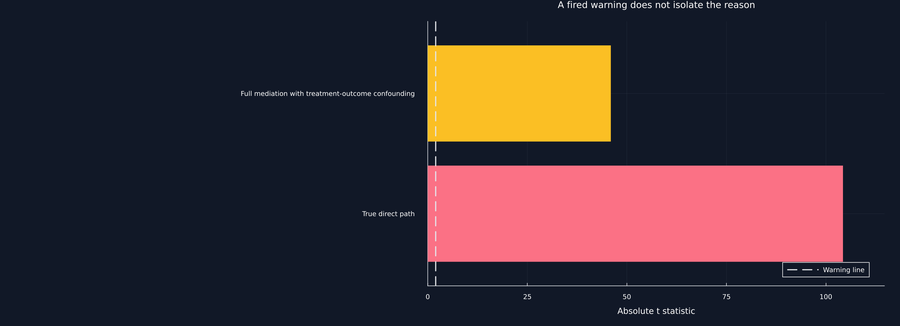

Row,Check,Observed,Expected,Passed,Expected result,Observed result
,String,Float64?,Float64?,String,String?,String?
1,Known-effect recovery,0.833963,0.84,Yes,missing,missing
2,Bundle product identity,0.833963,0.833963,Yes,missing,missing
3,Zero-sensitivity collapse,0.0,0.0,Yes,missing,missing
4,Unequal lengths,missing,missing,Yes,Rejected,Rejected
5,Too few observations,missing,missing,Yes,Rejected,Rejected
6,Negative sensitivity strength,missing,missing,Yes,Rejected,Rejected
7,Two-dimensional treatment,missing,missing,Yes,Rejected,Rejected


Row,Question,Answer
,String,String
1,Can an unmeasured treatment-outcome common cause remain?,"Yes, under the front-door conditions"
2,Must the mediator carry the whole treatment effect?,Yes
3,Can mediator-outcome confounding be ignored?,No
4,Does the sensitivity interval prove the assumptions?,No
5,Does a fired direct-path warning identify one cause?,No


In [6]:
direct_rows = Tuple[]
for (index,(name,direct)) in enumerate([("True direct path",.6),("Full mediation with treatment-outcome confounding",0.)])
    x,m,y,u,truth = simulate_frontdoor(store,"fd_direct",index;direct)
    warning = direct_path_test(x,m,y)
    push!(direct_rows,(name,direct,warning.coef,warning.se,abs(warning.tstat),warning.fired))
end
direct_path_caveat = frame(["Case","True direct effect","Fitted direct coefficient","Standard error","Absolute t statistic","Warning fired"],direct_rows)
table(select(direct_path_caveat,["Case","Fitted direct coefficient","Absolute t statistic","Warning fired"]),"frontdoor_direct_path_caveat","Direct-path warning in two cases that both trigger it.")
save_data(direct_path_caveat,paths,"frontdoor_direct_path_details")
figure = bar(1:2,direct_path_caveat[!,"Absolute t statistic"];orientation=:horizontal,color=[palette.rose,palette.amber],linealpha=0,label="",yticks=(1:2,["True direct path","Full mediation with treatment-outcome confounding"]),ylims=(.4,2.6),xlims=(0,1.1maximum(direct_path_caveat[!,"Absolute t statistic"])),xlabel="Absolute t statistic",title="A fired warning does not isolate the reason",legend=:bottomright,left_margin=108Plots.mm,size=(1600,580))
vline!(figure,[2.];color=palette.text,linestyle=:dash,label="Warning line")
save_figure(figure,paths,"frontdoor_direct_path_caveat")
x,m,y,u,truth = simulate_frontdoor(store,"fd_large";a=1.2,b=.7)
known_beta = frontdoor_premium(x,m,y)
bundle = frontdoor_analysis(x,m,y)
check_rows = Tuple[("Known-effect recovery",known_beta,truth,abs(known_beta-truth)<.03,missing,missing),("Bundle product identity",bundle.premium,bundle.a_hat*bundle.b_hat,bundle.premium≈bundle.a_hat*bundle.b_hat,missing,missing),("Zero-sensitivity collapse",bundle.sensitivity[0.][2]-bundle.sensitivity[0.][1],0.,bundle.sensitivity[0.][2]≈bundle.sensitivity[0.][1],missing,missing)]
for check in [contract_result("Unequal lengths",()->frontdoor_premium(zeros(9),zeros(10),zeros(10)),DimensionMismatch),contract_result("Too few observations",()->frontdoor_premium(zeros(2),zeros(2),zeros(2)),ArgumentError),contract_result("Negative sensitivity strength",()->frontdoor_sensitivity_interval(zeros(10),zeros(10),zeros(10),-.1),ArgumentError),contract_result("Two-dimensional treatment",()->frontdoor_premium(zeros(10,2),zeros(10),zeros(10)),ArgumentError)]
    push!(check_rows,(check[1],missing,missing,check[4],check[2],check[3]))
end
contract_checks = frame(["Check","Observed","Expected","Passed","Expected result","Observed result"],check_rows)
frontdoor_summary = frame(["Question","Answer"],[["Can an unmeasured treatment-outcome common cause remain?","Yes, under the front-door conditions"],["Must the mediator carry the whole treatment effect?","Yes"],["Can mediator-outcome confounding be ignored?","No"],["Does the sensitivity interval prove the assumptions?","No"],["Does a fired direct-path warning identify one cause?","No"]])
table(contract_checks,"frontdoor_contract_checks","Known-value and input checks for the released front-door calculations.")
table(frontdoor_summary,"frontdoor_section_summary","Main conclusions from the front-door experiments.")
save_data(DataFrame("First slope"=>[bundle.a_hat],"Second slope"=>[bundle.b_hat],"Front-door estimate"=>[bundle.premium],"Ordinary estimate"=>[bundle.ols_premium],"Wedge"=>[bundle.wedge]),paths,"frontdoor_large_details")
nothing


## Tests

In [7]:
@assert recovery_summary[1,"Mean squared error"]<=.02
@assert recovery_summary[2,"Mean squared error"]>=.15
@assert abs(mean(fd_values)-1.)<.05
@assert maximum(convergence_table[!,"Mean squared error"])<=.02
@assert issorted(wedge_sweep[!,"Mean wedge"])
@assert sensitivity_coverage[4,"Coverage"]>=.80
@assert sensitivity_coverage[5,"Coverage"]>=.90
@assert all(diff(sensitivity_intervals.Width).>=-1e-12)
@assert all(direct_path_caveat[!,"Warning fired"])
@assert all(contract_checks.Passed)
assert_artifacts(["frontdoor_graph","frontdoor_demo_comparison","frontdoor_estimate_distributions","frontdoor_convergence_mse","frontdoor_wedge_sweep","frontdoor_sensitivity_coverage","frontdoor_sensitivity_intervals","frontdoor_direct_path_caveat"],["frontdoor_conditions","frontdoor_structural_parameters","frontdoor_demo","frontdoor_recovery_summary","frontdoor_convergence","frontdoor_wedge_sweep","frontdoor_sensitivity_coverage","frontdoor_sensitivity_intervals","frontdoor_direct_path_caveat","frontdoor_contract_checks","frontdoor_section_summary"])
nothing
